In [1]:
import cupy as cp
import matplotlib.pyplot as plt

from tqdm.notebook import tqdm 

import seaborn as sns 

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "axes.labelsize": 12,
    "font.size": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

In [10]:
q = 4
J_corsivo = 1
J = J_corsivo * 2**((q-1)/2) / cp.sqrt(q)
T = 0.01
beta = 1/T
M=200 # Number of iterations for the solver


In [11]:
x= 0.5

S = 2**(int(cp.log2(100000))+2)

t_values = cp.linspace(0, beta, S, endpoint=False)
N_max = (S-1) // 4

n = cp.fft.fftfreq(S)*S
dealias_mask = cp.abs(n) <= N_max

omega = 2*cp.pi/beta*(n + 0.5)
phase_shift = cp.exp(-1j*cp.pi/beta*t_values)

G_t = cp.full(t_values.size, 0.5)

G = 1.0 / (1j*omega)
G_free = G

diff = cp.empty((M), dtype=cp.float64)

for i in range(M):
    if i>= 2:
        check = diff[i-1]-diff[i-2]
        if check > 0:
            x = x/2.0

    Sigma_t = J**2 *cp.power(G_t, q-1)
    Sigma = cp.fft.fft(Sigma_t * phase_shift)
    Sigma *= dealias_mask
    Sigma *= beta/S
    

    G_new = (1-x)*G + x/(1j*omega-Sigma)
    Delta_G = G_new - G_free
    Delta_G *= dealias_mask

    G_new_t = 0.5 + cp.real(S/beta * cp.fft.ifft(Delta_G) * phase_shift.conj())
    diff[i] = cp.sum(cp.abs(G_new_t-G_t)**2)*beta/S

    G = G_new
    G_t = G_new_t


In [12]:
G_c = cp.empty(t_values.size-2, dtype=cp.complex64)
Delta = 1/q
b = (cp.tan(cp.pi*Delta)*(0.5-Delta)/(J**2 * cp.pi))**(1/q)
theta = 2*cp.pi/beta*t_values
theta_cut = theta[1:-1]
i = cp.ogrid[:(t_values.size-2)]
G_c[:] = b*(cp.pi/(beta*cp.sin(theta_cut[i]/2)))**(2*Delta)

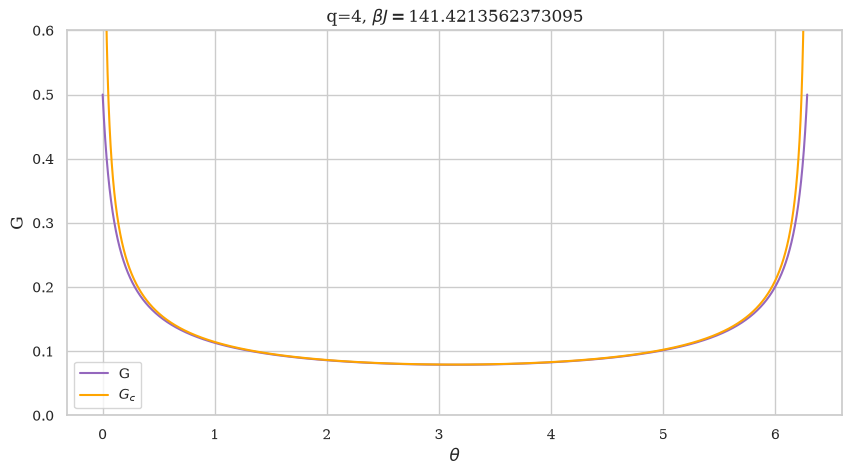

In [13]:
theta_CPU = theta.get()
theta_cut_CPU = theta_cut.get()
reale = G_t.real.get()
immag = G_t.imag.get()
G_t_CPU = G_t.real.get()

plt.figure(figsize=(10, 5))
plt.plot(theta_CPU, reale, color="tab:purple", label="G")
plt.plot(theta_cut_CPU, G_c.real.get(), color="orange", label=fr'$G_c$')


plt.xlabel(fr'$\theta$')
plt.ylabel(fr'G')
plt.title(fr'q={q}, $\beta J =${beta*J}')

plt.ylim(0,0.6)
plt.legend()
plt.show()